# Практическое занятие 6. Разбиение заказов на выборки

Задача — подготовить train, validation и test для прогноза `late` в момент создания заказа. Используется фактически предоставленный `orders_dirty.csv` в папке `lb6`. Исходный CSV не изменяется. Выберите ядро **Python (lb6)** и выполните **Restart & Run All**.

## 1. Загрузка и аудит исходных данных

В тексте задания указано 121 × 10. Размер фактически предоставленного файла проверяем отдельно; дальнейшие результаты относятся именно к нему.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

root = Path.cwd()
raw = pd.read_csv(root / 'orders_dirty.csv')
dictionary = pd.read_csv(root / 'data_dictionary.csv')
print('Фактический размер N × p:', raw.shape)
print('Пропуски по полям:')
print(raw.isna().sum().to_string())
print('Типы полей:')
print(raw.dtypes.to_string())

Фактический размер N × p: (600, 10)
Пропуски по полям:
order_id            0
created_at          0
distance_km         0
queue_size          1
weather             1
zone                0
promised_minutes    0
actual_minutes      0
late                0
vehicle_type        0
Типы полей:
order_id                str
created_at              str
distance_km             str
queue_size          float64
weather                 str
zone                    str
promised_minutes      int64
actual_minutes        int64
late                  int64
vehicle_type            str


### 1.1. Полные дубликаты и проверка исторической метки

Для аудита сравниваем `late` с правилом `actual_minutes − promised_minutes > 15`. Фактическая длительность известна после доставки, поэтому не будет признаком модели.

In [2]:
duplicate = raw.duplicated()
actual = pd.to_numeric(raw['actual_minutes'], errors='coerce')
promised = pd.to_numeric(raw['promised_minutes'], errors='coerce')
historical_late = pd.to_numeric(raw['late'], errors='coerce')
valid_audit = actual.notna() & promised.notna() & historical_late.isin([0, 1])
label_conflict = valid_audit & ((actual - promised > 15).astype(int) != historical_late)
print('Полных дублей:', int(duplicate.sum()))
print('Расхождений метки:', int(label_conflict.sum()))
print('Невалидных строк для аудита:', int((~valid_audit).sum()))
print(raw.loc[duplicate | label_conflict,
              ['order_id', 'promised_minutes', 'actual_minutes', 'late']].to_string(index=False))

Полных дублей: 1
Расхождений метки: 1
Невалидных строк для аудита: 0
order_id  promised_minutes  actual_minutes  late
ORD-0035                68              71     1
ORD-0020                69              79     0


## 2. Рабочая копия и состав X и y

Полный дубль и запись с конфликтной меткой исключаем до разбиения. Другие наблюдения, в том числе необычные расстояния и пропуски признаков, пока сохраняем. Заполнение пропусков и кодирование категорий не выполняем до выделения train.

In [3]:
work = raw.loc[~duplicate & ~label_conflict].copy()
work['created_at'] = pd.to_datetime(work['created_at'], errors='coerce')
assert work['created_at'].notna().all(), 'В рабочей копии есть неразбираемые даты'
assert work['order_id'].notna().all() and work['order_id'].is_unique
assert work['late'].isin([0, 1]).all()
cleaning = pd.DataFrame([
    ['Сырой набор', 'Без изменений', len(raw), len(raw)],
    ['Убрать полный дубль', 'Повторная идентичная строка', len(raw), len(raw)-int(duplicate.sum())],
    ['Убрать конфликт метки', 'late не соответствует правилу >15 мин',
     len(raw)-int(duplicate.sum()), len(work)]
], columns=['Действие', 'Причина', 'N до', 'N после'])
print(cleaning.to_string(index=False))
print('Итоговый размер рабочей копии:', work.shape)

             Действие                               Причина  N до  N после
          Сырой набор                         Без изменений   600      600
  Убрать полный дубль           Повторная идентичная строка   600      599
Убрать конфликт метки late не соответствует правилу >15 мин   599      598
Итоговый размер рабочей копии: (598, 10)


In [4]:
feature_columns = ['distance_km', 'queue_size', 'weather', 'zone',
                   'promised_minutes', 'vehicle_type']
known_at = dictionary.set_index('field').loc[feature_columns, 'known_at']
assert known_at.eq('при создании').all(), 'В X есть поле, недоступное в момент прогноза'
assert dictionary.set_index('field').loc['actual_minutes', 'known_at'] == 'после доставки'
print('Доступность признаков по словарю:')
print(known_at.to_string())
X = work[feature_columns].copy()
y = work['late'].astype(int).copy()
print('X в момент создания заказа:', ', '.join(feature_columns))
print('y:', y.name)
print('created_at — только порядок для временной схемы; производные из него возможны позднее.')
print('order_id — только контроль состава частей.')
print('actual_minutes — результат после доставки; включение в X дало бы утечку.')

Доступность признаков по словарю:
field
distance_km         при создании
queue_size          при создании
weather             при создании
zone                при создании
promised_minutes    при создании
vehicle_type        при создании
X в момент создания заказа: distance_km, queue_size, weather, zone, promised_minutes, vehicle_type
y: late
created_at — только порядок для временной схемы; производные из него возможны позднее.
order_id — только контроль состава частей.
actual_minutes — результат после доставки; включение в X дало бы утечку.


## 3. Случайное стратифицированное разбиение 60/20/20

На первом этапе отделяем 20% теста от 80% разработки; на втором выделяем 25% от разработки под validation. В обоих вызовах `stratify` использует метку класса, `random_state=42`.

In [5]:
development, random_test = train_test_split(
    work, test_size=.20, stratify=y, random_state=42)
random_train, random_val = train_test_split(
    development, test_size=.25, stratify=development['late'], random_state=42)
random_parts = {'train': random_train, 'validation': random_val, 'test': random_test}
random_X = {name: frame[feature_columns].copy() for name, frame in random_parts.items()}
random_y = {name: frame['late'].astype(int).copy() for name, frame in random_parts.items()}
assert all(list(features.columns) == feature_columns for features in random_X.values())
print('Этап 1: development =', len(development), ', test =', len(random_test))
print('Этап 2: train =', len(random_train), ', validation =', len(random_val))
print('Итого:', sum(len(part) for part in random_parts.values()))

Этап 1: development = 478 , test = 120
Этап 2: train = 358 , validation = 120
Итого: 598


In [6]:
def class_summary(parts):
    rows=[]
    for name, frame in parts.items():
        n=len(frame)
        n1=int((frame['late']==1).sum())
        rows.append({'Часть':name,'N':n,'late=0':n-n1,'late=1':n1,
                     'late=1, %':100*n1/n})
    return pd.DataFrame(rows)

baseline=class_summary({'рабочая копия':work})
random_summary=class_summary(random_parts)
print(pd.concat([baseline,random_summary],ignore_index=True).round(2).to_string(index=False))

        Часть   N  late=0  late=1  late=1, %
рабочая копия 598     318     280      46.82
        train 358     190     168      46.93
   validation 120      64      56      46.67
         test 120      64      56      46.67


## 4. Проверки непересечения, полноты и повторяемости

Проверяем именно `order_id`: разные строки с одинаковым заказом могли бы иметь разные индексы. Одной проверки индексов недостаточно, особенно после их сброса или объединения таблиц.

In [7]:
def check_partition(parts, source_ids):
    ids={name:set(frame['order_id']) for name,frame in parts.items()}
    assert all(frame['order_id'].is_unique for frame in parts.values())
    assert ids['train'].isdisjoint(ids['validation'])
    assert ids['train'].isdisjoint(ids['test'])
    assert ids['validation'].isdisjoint(ids['test'])
    assert set.union(*ids.values()) == set(source_ids)
    assert sum(len(frame) for frame in parts.values()) == len(source_ids)
    return ids

random_ids=check_partition(random_parts,work['order_id'])
development_again,test_again=train_test_split(work,test_size=.20,stratify=y,random_state=42)
train_again,val_again=train_test_split(development_again,test_size=.25,
                                       stratify=development_again['late'],random_state=42)
assert random_train['order_id'].tolist()==train_again['order_id'].tolist()
assert random_val['order_id'].tolist()==val_again['order_id'].tolist()
assert random_test['order_id'].tolist()==test_again['order_id'].tolist()
print('Проверки ID, полноты и повторяемости random_state=42 пройдены.')

Проверки ID, полноты и повторяемости random_state=42 пройдены.


## 5. Хронологическое разбиение 60/20/20

Сортируем по `created_at`, при совпадении времени — по `order_id`. Разрезаем последовательность без перемешивания; границы округляем до целых строк.

In [8]:
chronological=work.sort_values(['created_at','order_id'],kind='mergesort').copy()
n=len(chronological)
n_train=round(.60*n)
n_val=round(.20*n)
time_train=chronological.iloc[:n_train].copy()
time_val=chronological.iloc[n_train:n_train+n_val].copy()
time_test=chronological.iloc[n_train+n_val:].copy()
time_parts={'train':time_train,'validation':time_val,'test':time_test}
time_X = {name: frame[feature_columns].copy() for name, frame in time_parts.items()}
time_y = {name: frame['late'].astype(int).copy() for name, frame in time_parts.items()}
assert all(list(features.columns) == feature_columns for features in time_X.values())
time_ids=check_partition(time_parts,work['order_id'])
assert time_train['created_at'].max() < time_val['created_at'].min()
assert time_val['created_at'].max() < time_test['created_at'].min()
time_summary=class_summary(time_parts)
time_summary['Дата min']=[part['created_at'].min() for part in time_parts.values()]
time_summary['Дата max']=[part['created_at'].max() for part in time_parts.values()]
print(time_summary.to_string(index=False, float_format=lambda value: f'{value:.2f}'))
print('Хронология, непересечение периодов и ID проверены.')

     Часть   N  late=0  late=1  late=1, %            Дата min            Дата max
     train 359     198     161      44.85 2026-08-25 08:00:00 2026-09-28 03:36:00
validation 120      65      55      45.83 2026-09-28 05:33:00 2026-10-06 04:39:00
      test 119      55      64      53.78 2026-10-06 06:36:00 2026-10-15 05:06:00
Хронология, непересечение периодов и ID проверены.


## 6. Сравнение схем

Стратификация поддерживает близкие доли класса и удобна для стабильной оценки при случайном срезе. Временная схема отражает прогноз для будущих заказов, но доля класса может меняться со временем; специально выравнивать её здесь не нужно. Ни одна схема сама по себе не предотвращает утечку при подготовке признаков.

             Схема      Часть   N  late=0  late=1  late=1, %
Стратифицированная      train 358     190     168      46.93
Стратифицированная validation 120      64      56      46.67
Стратифицированная       test 120      64      56      46.67
   Хронологическая      train 359     198     161      44.85
   Хронологическая validation 120      65      55      45.83
   Хронологическая       test 119      55      64      53.78


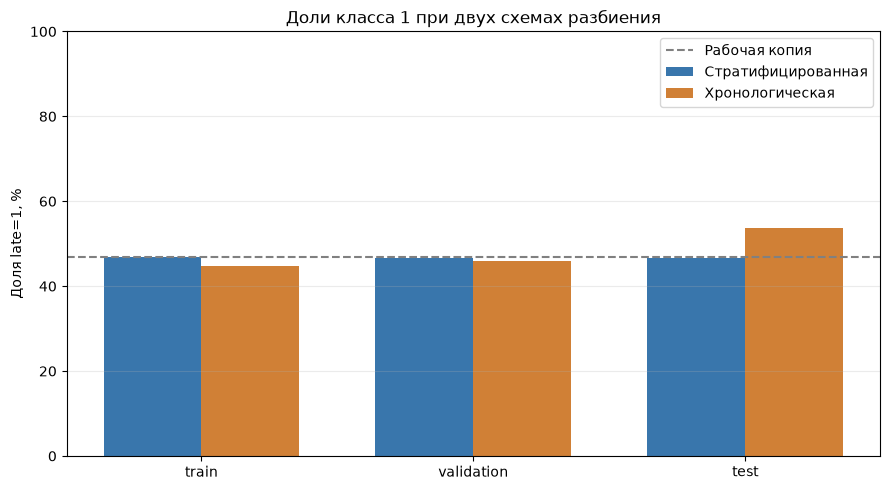

In [9]:
comparison=pd.concat([
    random_summary.assign(Схема='Стратифицированная'),
    time_summary[['Часть','N','late=0','late=1','late=1, %']].assign(Схема='Хронологическая')
],ignore_index=True)[['Схема','Часть','N','late=0','late=1','late=1, %']]
print(comparison.round(2).to_string(index=False))

fig,ax=plt.subplots(figsize=(9,5))
parts=['train','validation','test']
positions=range(len(parts))
ax.bar([i-.18 for i in positions],random_summary['late=1, %'],width=.36,
       label='Стратифицированная',color='#3976ac')
ax.bar([i+.18 for i in positions],time_summary['late=1, %'],width=.36,
       label='Хронологическая',color='#d08036')
ax.axhline(float(baseline.loc[0,'late=1, %']),color='gray',linestyle='--',
           label='Рабочая копия')
ax.set(xticks=list(positions),xticklabels=parts,ylabel='Доля late=1, %',
       title='Доли класса 1 при двух схемах разбиения',ylim=(0,100))
ax.legend()
ax.grid(axis='y',alpha=.25)
fig.tight_layout()
fig.savefig(root/'06_split_comparison.png',dpi=150)
plt.show()

## 7. Сохранение состава частей и итоговые проверки

CSV содержат `order_id`, историческую метку, дату и имя части. Они позволяют повторно сверить состав выборок, не сохраняя преобразованные признаки или обученную модель.

In [10]:
def save_manifest(parts,filename):
    manifest=pd.concat([
        frame[['order_id','late','created_at']].assign(split=name)
        for name,frame in parts.items()
    ],ignore_index=True)
    manifest.to_csv(root/filename,index=False)
    saved=pd.read_csv(root/filename)
    assert len(saved)==len(work)
    assert saved['order_id'].is_unique
    assert set(saved['order_id'])==set(work['order_id'])
    expected_labels=manifest.set_index('order_id')['late'].sort_index()
    saved_labels=saved.set_index('order_id')['late'].sort_index()
    assert saved_labels.equals(expected_labels)
    for name,frame in parts.items():
        assert set(saved.loc[saved['split']==name,'order_id'])==set(frame['order_id'])
    return manifest

random_manifest=save_manifest(random_parts,'06_stratified_splits.csv')
time_manifest=save_manifest(time_parts,'06_chronological_splits.csv')
print('Сохранены 06_stratified_splits.csv и 06_chronological_splits.csv')
print('N = N_train + N_val + N_test:',len(work),'=',
      len(random_train),'+',len(random_val),'+',len(random_test))

Сохранены 06_stratified_splits.csv и 06_chronological_splits.csv
N = N_train + N_val + N_test: 598 = 358 + 120 + 120


## 8. Утечки, ограничения и вывод

**Сценарии утечки.** (1) `actual_minutes` раскрывает исход после доставки — исключён из X. (2) Среднее для заполнения пропусков, параметры масштабирования и категории кодировщика, вычисленные по всей таблице, используют сведения validation/test; такие преобразования нужно обучать только на train. (3) Повтор заказа в разных частях переносит информацию между выборками; дубль удалён до деления, а множества ID проверены. (4) Случайный split смешивает прошлое и будущее; для проверки прогноза будущих заказов дополнительно показана хронологическая схема.

Validation служит для выбора параметров и решений по модели. Test оставляют нетронутым до финальной оценки. Классификатор в этой работе не обучается.